# EcoData · S10 — Series de tiempo e inferencia en streaming (dimensión clima)
**Alahin Reyme Ticona Veliz** · Proyecto Sello EcoData (dimensión **clima / temperatura**, Juliaca) · Big Data, UPeU

La guía predice `CE(t+1)` con `lead()`, compara contra **persistencia** y aplica el modelo en vivo sin estado. En EcoData clima la variable es **temperatura a +1 hora** (Juliaca), de la que depende el aviso de helada:

| Guía S10 | EcoData · clima |
|---|---|
| Gold de S04 | histórico real de Open-Meteo de Juliaca (`clima_juliaca_2023.json`, 8 760 h) |
| `label = lead("CE", 1)` | `delta = lead(temp,1) − temp` (cambio a +1 h; predecir el cambio y sumarlo equivale a predecir la temperatura y evita que los árboles tengan que «extrapolar»), verificando que la hora siguiente es consecutiva |
| 8 variables del mismo instante | `temp`, `hum`, `viento` y la **hora del día objetivo** (seno/coseno), calculadas **dentro del Pipeline** |
| baseline | **dos**: persistencia (`T(t+1)=T(t)`) y **persistencia estacional diaria** (el cambio de la misma hora de ayer), porque la temperatura tiene un ciclo diurno fuerte |
| productor `campo-electrico-eventos` | topic **`ecodata-clima-s10`**, horas reales de la **cola del conjunto de prueba** a ritmo controlado |

> **Relación con el modelo de producción (S12):** el modelo que alimenta Grafana usa 24 h de historial (`clima_comun.FEATURES`) y también predice el *delta* (MAE 1,234 de persistencia frente a 0,571 lineal y 0,646 GBT, ≈ 47,7 % de mejora). Éste de S10 es **más simple a propósito** (sin estado) para cumplir la mecánica de la guía y comparar con honestidad. El resultado puede ser mejor o peor: se reporta tal cual.
>
> **Transparencia:** el «stream» es el reenvío de horas reales de prueba (`origen = openmeteo-replay`), una cada 3 s. Cierra otros cuadernos de Spark antes de ejecutar.

## 0. Preparación y SparkSession

In [1]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import clima_comun as clima
import openmeteo_clima_a_kafka as pub_clima
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"
HISTORICO = "/tmp/s12/clima_juliaca_2023.json"      # temperatura, humedad y viento horarios reales (Open-Meteo), ya en el proyecto

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: v if isinstance(v, bytes) else json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path=HISTORICO):
    """[(ts_ms, temp, hum, viento)] ordenado y sin huecos, del histórico real del proyecto."""
    return clima.leer_json(path)

def serie_clima(min_horas=96):
    """Primero la API (horas recientes); si trae pocas (suele dar ~50 h), el histórico real. Devuelve (serie, origen)."""
    try:
        s = pub_clima.desde_api(); origen = "openmeteo-api"
    except Exception as ex:
        print("API no disponible:", type(ex).__name__); s, origen = [], "openmeteo-api"
    if len(s) < min_horas:
        print(f"La API trajo {len(s)} horas; uso el histórico real de Juliaca (origen openmeteo-replay)")
        s, origen = desde_archivo(), "openmeteo-replay"
    return s, origen

TOPIC = "ecodata-clima-s10"
crear_topic(TOPIC)

topic creado: ecodata-clima-s10


In [2]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("temp", DoubleType()).add("hum", DoubleType()).add("viento", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-clima-s10").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4061")          # puertos 4060-4063: no chocan con 4040 (S12) ni con 4050-4053 (aire)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, SQLTransformer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a866da53-a410-48a6-a1fa-dd8da51d5543;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0


## 1. Business Understanding (3.1.2)
**Objetivo:** estimar la temperatura de la **hora siguiente** (`T(t+1)`) a partir de la lectura actual (temperatura, humedad, viento y hora del día), para anticipar heladas (T < 0 °C).
**Alcance:** comparar dos baselines, LinearRegression, RandomForest y GBT con división cronológica y RMSE/MAE/R², revisar qué tan bien detectan las heladas, y aplicar el ganador en tiempo real.

## 2. Dataset supervisado con `lead()` y división cronológica (3.2–3.3)

In [3]:
filas = desde_archivo()                                   # [(ts_ms, temp, hum, viento)]
df = spark.createDataFrame(filas, ["timestamp", "temp", "hum", "viento"])
orden = Window.orderBy("timestamp")
H = 3600_000
ds = (df.withColumn("temp_sig", F.lead("temp", 1).over(orden))
        .withColumn("ts_sig", F.lead("timestamp", 1).over(orden))
        .withColumn("temp_ayer0", F.lag("temp", 24).over(orden)).withColumn("temp_ayer1", F.lag("temp", 23).over(orden))
        .withColumn("ts_ayer0", F.lag("timestamp", 24).over(orden)))
total = ds.count()
ds = (ds.na.drop()
        .filter((F.col("ts_sig") - F.col("timestamp") == H) & (F.col("timestamp") - F.col("ts_ayer0") == 24 * H))   # solo horas consecutivas
        .withColumn("label", F.col("temp_sig") - F.col("temp"))                       # delta a +1 h
        .withColumn("delta_ayer", F.col("temp_ayer1") - F.col("temp_ayer0"))          # baseline estacional diario
        .select("timestamp", "temp", "hum", "viento", "temp_sig", "label", "delta_ayer"))
print(f"Filas históricas: {total:,} · filas del dataset supervisado: {ds.count():,} (se descartan la última, las primeras 24 h y cualquier hueco)")
ds.orderBy("timestamp").show(5)

Filas históricas: 8,760 · filas del dataset supervisado: 8,735 (se descartan la última, las primeras 24 h y cualquier hueco)
+-------------+----+---+------+--------+-------------------+--------------------+
|    timestamp|temp|hum|viento|temp_sig|              label|          delta_ayer|
+-------------+----+---+------+--------+-------------------+--------------------+
|1672617600000|10.0| 78|   5.8|     8.9|-1.0999999999999996|-0.40000000000000036|
|1672621200000| 8.9| 82|  10.0|     7.8|-1.1000000000000005| -1.0999999999999996|
|1672624800000| 7.8| 82|  12.9|     6.9|-0.8999999999999995|                -2.2|
|1672628400000| 6.9| 91|  10.9|     7.4|                0.5| -0.3999999999999999|
|1672632000000| 7.4| 87|   2.4|     6.8|-0.6000000000000005|  0.8999999999999999|
+-------------+----+---+------+--------+-------------------+--------------------+
only showing top 5 rows


In [4]:
num = ds.withColumn("n", F.row_number().over(orden))
corte = int(num.count() * 0.80)
train = num.filter(F.col("n") <= corte).drop("n"); test = num.filter(F.col("n") > corte).drop("n")
fmax_train = train.agg(F.max("timestamp")).first()[0]; fmin_test = test.agg(F.min("timestamp")).first()[0]
assert fmax_train < fmin_test, "La división no respeta el orden cronológico"
f = lambda ms: pd.to_datetime(ms, unit="ms")
print(f"Entrenamiento: {train.count():,} filas (hasta {f(fmax_train)} UTC)")
print(f"Prueba:        {test.count():,} filas (desde {f(fmin_test)} UTC) → sin fuga de información")

Entrenamiento: 6,988 filas (hasta 2023-10-20 03:00:00 UTC)
Prueba:        1,747 filas (desde 2023-10-20 04:00:00 UTC) → sin fuga de información


## 3. Baselines, calculados ANTES de entrenar (3.4.1)
Se evalúa el cambio `delta` (el error de predecir el delta es el mismo que el de predecir la temperatura, porque `T(t+1) = T(t) + delta`).
- **Persistencia:** `T(t+1)=T(t)` ⇒ delta predicho = 0.
- **Estacional diaria:** el delta de la misma hora de ayer (`delta_ayer`).

In [5]:
ev = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}
def evaluar(pred, nombre):
    r = {"Modelo": nombre, "RMSE": ev["rmse"].evaluate(pred), "MAE": ev["mae"].evaluate(pred), "R2": ev["r2"].evaluate(pred)}
    print(f"{nombre}: RMSE={r['RMSE']:.4f}  MAE={r['MAE']:.4f}  R2={r['R2']:.4f}"); return r
res_pers = evaluar(test.withColumn("prediction", F.lit(0.0)), "Persistencia (T_t+1 = T_t)")
res_est  = evaluar(test.withColumn("prediction", F.col("delta_ayer")), "Estacional diaria (delta de ayer)")

Persistencia (T_t+1 = T_t): RMSE=1.4076  MAE=1.0963  R2=-0.0000
Estacional diaria (delta de ayer): RMSE=1.0560  MAE=0.6982  R2=0.4371


## 4. Modelado comparado (3.4.2–3.5.1)
La hora del día **objetivo** (hora de `t`+1) se calcula **dentro del Pipeline** (`SQLTransformer`), de modo que en producción el modelo solo necesita las columnas del evento.

In [6]:
HORA = SQLTransformer(statement="""SELECT *,
    sin(2 * pi() * ((hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) + 1) % 24) / 24) AS h_sin,
    cos(2 * pi() * ((hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) + 1) % 24) / 24) AS h_cos FROM __THIS__""")
ENS = VectorAssembler(inputCols=["temp", "hum", "viento", "h_sin", "h_cos"], outputCol="features")
candidatos = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol="label"),
    "RandomForestRegressor": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=8, seed=42),
    "GBTRegressor": GBTRegressor(featuresCol="features", labelCol="label", maxIter=40, maxDepth=5, seed=42),
}
modelos, resultados = {}, [res_pers, res_est]
for nombre, est in candidatos.items():
    m = Pipeline(stages=[HORA, ENS, est]).fit(train); modelos[nombre] = m
    resultados.append(evaluar(m.transform(test), nombre))
comp = pd.DataFrame(resultados)
comp["Mejora RMSE vs persistencia %"] = 100 * (res_pers["RMSE"] - comp["RMSE"]) / res_pers["RMSE"]
comp["Mejora MAE vs persistencia %"] = 100 * (res_pers["MAE"] - comp["MAE"]) / res_pers["MAE"]
comp["Mejora RMSE vs estacional %"] = 100 * (res_est["RMSE"] - comp["RMSE"]) / res_est["RMSE"]
comp.round(4)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


LinearRegression: RMSE=1.0342  MAE=0.7421  R2=0.4602
RandomForestRegressor: RMSE=0.8220  MAE=0.5343  R2=0.6590
GBTRegressor: RMSE=0.8651  MAE=0.5717  R2=0.6223


,Modelo,RMSE,MAE,R2,Mejora RMSE vs persistencia %,Mejora MAE vs persistencia %,Mejora RMSE vs estacional %
0,Persistencia (T_t+1 = T_t),1.4076,1.0963,-0.0000,0.0000,0.0000,-33.2889
1,Estacional diaria (delta de ayer),1.0560,0.6982,0.4371,24.9750,36.3181,0.0000
2,LinearRegression,1.0342,0.7421,0.4602,26.5260,32.3130,2.0673
3,RandomForestRegressor,0.8220,0.5343,0.6590,41.6028,51.2622,22.1630
4,GBTRegressor,0.8651,0.5717,0.6223,38.5419,47.8528,18.0831


## 5. Selección honesta (3.5.2)

In [7]:
mej = comp.iloc[2:].sort_values("RMSE").iloc[0]
ganador = mej["Modelo"]; margen = mej["Mejora RMSE vs persistencia %"]; margen_mae = mej["Mejora MAE vs persistencia %"]; margen_est = mej["Mejora RMSE vs estacional %"]
print(f"Mejor modelo por RMSE: {ganador} · mejora de RMSE vs persistencia: {margen:+.2f} % · de MAE: {margen_mae:+.2f} % · vs estacional: {margen_est:+.2f} %")
if margen <= 0:
    print("LECTURA: ningún modelo superó a la persistencia en RMSE → no se justifica desplegar; se guarda igual para la infraestructura (como pide la guía).")
elif margen < 3:
    print("LECTURA: el margen es mínimo → probablemente no justifica el costo de mantener un modelo entrenado; su valor está en la infraestructura de inferencia.")
else:
    print("LECTURA: el margen es apreciable → el modelo se justifica frente a la persistencia, con la salvedad de validar el error en producción (Regla #37, S11).")
if margen_est <= 0:
    print("ATENCIÓN: tampoco supera a la baseline estacional diaria; reportarlo así.")

Mejor modelo por RMSE: RandomForestRegressor · mejora de RMSE vs persistencia: +41.60 % · de MAE: +51.26 % · vs estacional: +22.16 %
LECTURA: el margen es apreciable → el modelo se justifica frente a la persistencia, con la salvedad de validar el error en producción (Regla #37, S11).


### 5.1 ¿Sirve para lo que importa: detectar heladas?
Para el negocio importa más acertar **si habrá helada** (T(t+1) < 0 °C) que el error medio. Se compara la detección del ganador con la de persistencia sobre el conjunto de prueba. (Las heladas son pocas: mira los conteos, no solo el porcentaje.)

In [8]:
pt = modelos[ganador].transform(test).select("temp", "temp_sig", F.col("prediction").alias("delta_pred")).toPandas()
pt["real"] = pt.temp_sig < 0
def tabla_det(pred_bool, nombre):
    tp = int((pred_bool & pt.real).sum()); fp = int((pred_bool & ~pt.real).sum()); fn = int((~pred_bool & pt.real).sum())
    return {"Método": nombre, "heladas reales": int(pt.real.sum()), "TP": tp, "FP": fp, "FN": fn,
            "precisión": round(tp / (tp + fp), 3) if tp + fp else None, "recall": round(tp / (tp + fn), 3) if tp + fn else None}
pd.DataFrame([tabla_det(pt.temp < 0, "Persistencia"), tabla_det((pt.temp + pt.delta_pred) < 0, ganador)])

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Método,heladas reales,TP,FP,FN,precisión,recall
0,Persistencia,0,0,0,0,None,None
1,RandomForestRegressor,0,0,0,0,None,None


In [9]:
filas = []
for u in (0, 1, 2, 3):
    real = pt.temp_sig < u
    for nombre, pred in (("Persistencia", pt.temp < u), (ganador, (pt.temp + pt.delta_pred) < u)):
        tp = int((pred & real).sum()); fp = int((pred & ~real).sum()); fn = int((~pred & real).sum())
        filas.append({"umbral °C": u, "método": nombre, "eventos reales": int(real.sum()), "TP": tp, "FP": fp, "FN": fn,
                      "precisión": round(tp/(tp+fp), 3) if tp+fp else None, "recall": round(tp/(tp+fn), 3) if tp+fn else None})
pd.DataFrame(filas)

,umbral °C,método,eventos reales,TP,FP,FN,precisión,recall
0,0,Persistencia,0,0,0,0,NaN,NaN
1,0,RandomForestRegressor,0,0,0,0,NaN,NaN
2,1,Persistencia,2,1,1,1,0.500,0.500
3,1,RandomForestRegressor,2,1,0,1,1.000,0.500
4,2,Persistencia,7,2,5,5,0.286,0.286
5,2,RandomForestRegressor,7,5,5,2,0.500,0.714
6,3,Persistencia,22,12,10,10,0.545,0.545
7,3,RandomForestRegressor,22,18,9,4,0.667,0.818


## 6. Guardar y recargar el PipelineModel (3.6.1)
Se guarda el **Pipeline completo** (hora del día + ensamblado + modelo) y se verifica que recargado predice lo mismo.

In [10]:
RUTA_MODELO = "./artifacts/models/modelo_temp_s10"
modelos[ganador].write().overwrite().save(RUTA_MODELO)
cargado = PipelineModel.load(RUTA_MODELO)
a = modelos[ganador].transform(test).select("timestamp", F.col("prediction").alias("antes"))
b = cargado.transform(test).select("timestamp", F.col("prediction").alias("despues"))
dif = a.join(b, "timestamp").agg(F.max(F.abs(F.col("antes") - F.col("despues")))).first()[0]
print("Modelo guardado y recargado en:", RUTA_MODELO)
print("Diferencia máxima entre predicciones antes/después de recargar:", dif)
assert dif < 1e-9

Modelo guardado y recargado en: ./artifacts/models/modelo_temp_s10
Diferencia máxima entre predicciones antes/después de recargar: 0.0


## 7. Inferencia en tiempo real, sin estado (3.7)
Se publican, a ritmo controlado, las últimas 40 horas **reales del conjunto de prueba**; el modelo recargado predice cada lectura tal como llega (sin ventanas ni watermark). La salida del modelo es el **cambio** a +1 h; la temperatura prevista es `temp + prediction`. Como las horas son consecutivas, la predicción de cada lectura se compara con la temperatura real de la hora siguiente.

In [11]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", "ecodata-clima-s10").option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
eventos = (crudo.select("topic", "partition", "offset", F.col("timestamp").alias("kafkaTimestamp"),
                        F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("topic", "partition", "offset", "kafkaTimestamp", "e.*"))
predicciones_stream = cargado.transform(eventos)          # el Pipeline guardado hace todo el trabajo
RUTA_PRED = "./artifacts/s10_predicciones_stream_clima"; CHK_PRED = "./artifacts/chk_s10_clima"
captura = []
def guardar(dfm, bid):
    n = dfm.count()
    if n == 0:
        captura.append(dict(batchId=bid, filas=0)); return
    out = dfm.select(F.lit(bid).alias("batchId"), "sensorId", "timestamp", "temp",
                     (F.col("temp") + F.col("prediction")).alias("pred_temp_siguiente"))
    out.write.mode("append").parquet(RUTA_PRED)
    for r in out.collect(): captura.append({**r.asDict(), "filas": n})

if "q" in dir() and q.isActive: q.stop()
q = predicciones_stream.writeStream.foreachBatch(guardar).option("checkpointLocation", CHK_PRED).start()
print("consulta activa:", q.isActive)

consulta activa: True


In [12]:
cola = test.orderBy(F.desc("timestamp")).limit(40).orderBy("timestamp").select("timestamp", "temp", "hum", "viento").collect()
eventos_pub = [clima.evento(r["timestamp"], r["temp"], r["hum"], r["viento"], "openmeteo-replay") for r in cola]
h = publicar_paced(TOPIC, eventos_pub, pausa_s=3.0)
print(len(eventos_pub), "eventos publicados a razón de 1 cada 3 s (≈ 2 min)")

40 eventos publicados a razón de 1 cada 3 s (≈ 2 min)


In [13]:
time.sleep(5)
print("micro-lotes con datos hasta ahora:", len([c for c in captura if c.get("filas")]))
for c in captura[-5:]: print(c)          # repite esta celda mientras corre la publicación

micro-lotes con datos hasta ahora: 4
{'batchId': 0, 'filas': 0}
{'batchId': 1, 'sensorId': 'openmeteo-clima-juliaca', 'timestamp': 1703919600000, 'temp': 6.6, 'pred_temp_siguiente': 6.259636267127943, 'filas': 1}
{'batchId': 2, 'sensorId': 'openmeteo-clima-juliaca', 'timestamp': 1703923200000, 'temp': 6.8, 'pred_temp_siguiente': 6.357714069795046, 'filas': 1}
{'batchId': 3, 'sensorId': 'openmeteo-clima-juliaca', 'timestamp': 1703926800000, 'temp': 7.0, 'pred_temp_siguiente': 6.602897525253905, 'filas': 1}
{'batchId': 4, 'sensorId': 'openmeteo-clima-juliaca', 'timestamp': 1703930400000, 'temp': 7.3, 'pred_temp_siguiente': 7.189885328253471, 'filas': 1}


In [14]:
h.join(timeout=180); time.sleep(10)
q.stop()
res = spark.read.parquet(RUTA_PRED).orderBy("timestamp").toPandas()
res["temp_real_siguiente"] = res["temp"].shift(-1)
aud = res.dropna()
mae_prod = (aud["pred_temp_siguiente"] - aud["temp_real_siguiente"]).abs().mean()
mae_pers = (aud["temp"] - aud["temp_real_siguiente"]).abs().mean()
print(f"Predicciones capturadas: {len(res)} · comparables: {len(aud)}")
print(f"MAE del modelo en el stream: {mae_prod:.4f} °C · MAE de persistencia en las mismas horas: {mae_pers:.4f} °C")
res.head(8)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Predicciones capturadas: 40 · comparables: 39
MAE del modelo en el stream: 0.6848 °C · MAE de persistencia en las mismas horas: 0.7513 °C


,batchId,sensorId,timestamp,temp,pred_temp_siguiente,temp_real_siguiente
0,1,openmeteo-clima-juliaca,1703919600000,6.6,6.259636,6.8
1,2,openmeteo-clima-juliaca,1703923200000,6.8,6.357714,7.0
2,3,openmeteo-clima-juliaca,1703926800000,7.0,6.602898,7.3
3,4,openmeteo-clima-juliaca,1703930400000,7.3,7.189885,7.4
4,5,openmeteo-clima-juliaca,1703934000000,7.4,8.914497,8.5
5,6,openmeteo-clima-juliaca,1703937600000,8.5,10.539655,8.7
6,7,openmeteo-clima-juliaca,1703941200000,8.7,10.501732,10.1
7,8,openmeteo-clima-juliaca,1703944800000,10.1,11.602849,11.0


Text(0, 0.5, '°C')

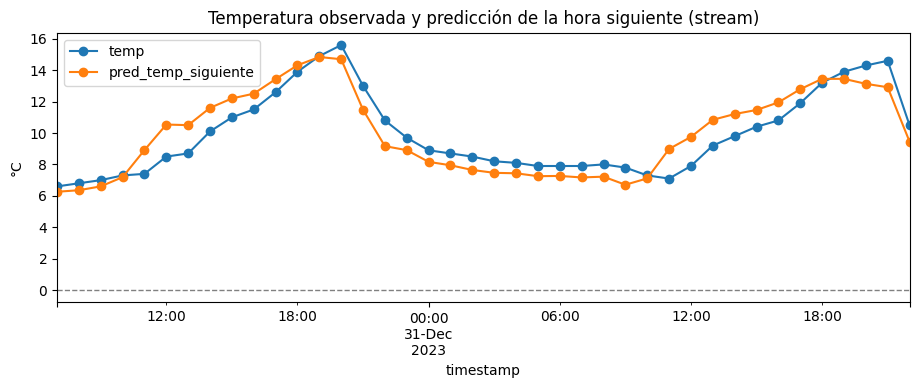

In [15]:
ax = res.set_index(pd.to_datetime(res.timestamp, unit="ms"))[["temp", "pred_temp_siguiente"]].plot(
        figsize=(11, 3.5), marker="o", title="Temperatura observada y predicción de la hora siguiente (stream)")
ax.axhline(0, color="gray", ls="--", lw=1); ax.set_ylabel("°C")

## 8. Hallazgo para el informe
Escribe un error o hallazgo **real** de tu ejecución. Candidatos que suelen aparecer: (a) `Micro-lote 0: sin filas` (no es un error); (b) horas no consecutivas descartadas al construir `label`; (c) el modelo que «gana» por un margen mínimo o pierde frente a persistencia o frente a la baseline estacional (caso M4); (d) `hour()` dependiente de la zona horaria: por eso `spark.sql.session.timeZone = UTC`; (e) pocas heladas en el conjunto de prueba: los porcentajes de la sección 5.1 se apoyan en pocos casos.

### Qué capturar (con **reloj del sistema y tu perfil visibles**)
1. Sección 2: `lead()`, conteos y división cronológica con fechas.
2. Sección 3: baselines. Sección 4: tabla comparativa. Sección 5 y 5.1: selección y detección de heladas.
3. Sección 6: guardado/recarga y diferencia ≈ 0.
4. Sección 7: bitácora del stream, tabla de predicciones, MAE y gráfico; Kafka UI → `ecodata-clima-s10`.

In [16]:
spark.stop()